# Predicting Tomorrow's Idle GPUs — 최종 분석

## 문제와 목표
LLM 추론 서비스는 요청이 없어도 GPU를 붙잡아 둔다. **내일 거의 쓰이지 않을 app**을 오늘 미리 알아내면
그 GPU를 회수해 다른 작업에 쓸 수 있다. 반대로 잘못 회수하면 다음날 요청이 들어올 때 **cold start**(다시 올리는 지연)가 생긴다.

- 목표: 운영자가 매일 쓰는 단순 규칙 **Baseline 1 ("오늘 거의 idle이면 내일도 회수")** 보다
  **같은 양을 회수하면서 cold start로 방해받는 작업을 줄이는** 예측 모델을 만든다.

## 데이터
- Alibaba MaaS trace v2026의 원시 표 세 개를 직접 가공해 데이터셋을 만들었다.
  - `instance_daily`: 인스턴스×일, 1.45억 행
  - `instance_week_5min`: 5분 단위, 1.41억 행
  - `app_metrics`: app 메타데이터
- 이 표들을 **app×day** 단위로 집계했다. 0–181일, 약 51만 행이다(`scripts/build_app_day_v2.py`).
- target: `is_mostly_idle_next`. **내일** idle 비율이 0.9 이상이면 1이다.
- 가중치: `gpu_hours_next`. 내일 그 app이 쓰는 GPU-h로, 큰 app의 실수가 더 크게 반영된다.
- 입력 변수: 23개, 6묶음(아래 1절).

## 방법
- 시간 순서를 지키는 **walk-forward 평가**를 한다.
  - 주 `[a, b]`를 예측할 때 `day ≤ a−2`의 데이터로만 학습한다(라벨이 하루 늦게 나오므로).
  - 평가 구간: test 주 140–146, 홀드아웃 5주 147–180. 모든 주를 직전 데이터로 다시 학습한다.
- 비교 대상:
  - 기준선: Baseline 1, Baseline 1′(idle_ratio 연속 점수), Baseline 2(오늘 sm_util이 가장 낮은 N개)
  - 모델: Logistic Regression, SVM(cuML), Random Forest, LightGBM, XGBoost, LightGBM+XGBoost 평균
- 하이퍼파라미터: v3 노트북의 4주 rolling CV + Optuna(GPU)로 골랐다.
- **운영 규칙(주 정책): 같은 날 B1과 같은 개수.**
  - 매일 Baseline 1이 회수하는 app 수 k만큼, 모델 점수 상위 k개를 회수한다.
  - threshold도 정답도 필요 없어서 그날 바로 쓸 수 있다.
  - 회수량이 B1과 같아지므로, 비교는 **누구를 고르느냐**로 좁혀진다.
- 참고 정책: v3와 같이 직전 주에서 threshold를 고르는 방식(F1 최대, 위험 맞춤)도 함께 보고한다.
- 불확실성: app 단위 부트스트랩 95% 구간.
- 실제 cold start 확인: 5분 단위 시뮬레이션(test 주).

## 최종 모델
**LightGBM 튜닝 + XGBoost 튜닝의 확률 평균**을, 같은 날 B1과 같은 개수 규칙으로 운영한다.
- 선택 근거(v4 견고성 실험):
  - 홀드아웃 5주에서 잘못 회수 GPU-h, 잘못 회수 건수, F1 모두 B1보다 유의하게 나았다.
  - seed 5개에서 효과의 방향이 같았다.
  - 학습 기간을 줄여도 나아지지 않았다.

## 0. 설정

In [1]:
# CUDA 라이브러리(cupy/cuml/xgboost)를 import하기 전에 실행해야 한다.
import os
import subprocess
import time


def gpu_status():
    out = subprocess.run(["nvidia-smi", "--query-gpu=index,utilization.gpu,memory.used",
                          "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    rows = []
    for line in out.splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) == 3 and all(p.isdigit() for p in parts):
            rows.append(tuple(map(int, parts)))
    return rows


def spare_gpus(n_samples=6, max_util=30, max_mem_mb=4000):
    # 잠깐 동안 여러 번 재서 최대 사용률·메모리가 기준 이하인 GPU만 고른다 (다른 사람이 쓰는 GPU 제외)
    peak = {}
    for _ in range(n_samples):
        for i, u, m in gpu_status():
            pu, pm = peak.get(i, (0, 0))
            peak[i] = (max(pu, u), max(pm, m))
        time.sleep(0.5)
    return [i for i, (u, m) in sorted(peak.items()) if u <= max_util and m <= max_mem_mb], peak


GPUS, peak = spare_gpus()
if os.environ.get("GPU_IDS"):
    GPUS = [int(x) for x in os.environ["GPU_IDS"].split(",")]
print("GPU 상태 (최대 사용률 %, 메모리 MiB):", peak)
assert GPUS, "남는 GPU가 없음"
os.environ["CUDA_VISIBLE_DEVICES"] = ",".join(map(str, GPUS))
N_GPU = len(GPUS)
DEVICES = list(range(N_GPU))   # CUDA_VISIBLE_DEVICES 안에서의 번호
print(f"사용할 GPU: 물리 번호 {GPUS} -> 장치 {DEVICES}")

GPU 상태 (최대 사용률 %, 메모리 MiB): {0: (100, 5779), 1: (0, 5)}
사용할 GPU: 물리 번호 [1] -> 장치 [0]


In [2]:
import json
import queue
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().resolve().parent          # notebooks/ 의 상위 = 프로젝트 루트
OUT = ROOT / "outputs" / "final"
V3_OUT = ROOT / "outputs" / "v3"
OUT.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 0

# 실행 규모 (시간이 부족하면 줄인다)
N_TRIALS = 40            # Optuna 시도 횟수 (모델당)
OPTUNA_TIMEOUT = 2400    # 모델당 최대 초
N_BOOT = 2000            # 부트스트랩 반복
SVM_TRAIN_N = None       # cuML SVC 학습 행 수 (None = train 전체; GPU에서 39만 행도 수 초)
SMOKE = os.environ.get("FINAL_SMOKE") == "1"   # 코드 점검용 축소 실행
if SMOKE:
    N_TRIALS, N_BOOT = 2, 50

import cupy as cp
import xgboost as xgb
import lightgbm as lgb
import optuna
from sklearn.metrics import average_precision_score

optuna.logging.set_verbosity(optuna.logging.WARNING)
print("cupy", cp.__version__, "| xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| optuna", optuna.__version__)
for d in DEVICES:
    print(f"  장치 {d}:", cp.cuda.runtime.getDeviceProperties(d)["name"].decode())

/ssd/jylee/gpu-reclaim/env-gpu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cupy 12.2.0 | xgboost 2.1.4 | lightgbm 4.6.0 | optuna 5.1.0
  장치 0: NVIDIA RTX A4000


## 1. 데이터와 변수

In [3]:
DATA = ROOT / "data" / "processed" / "app_day_v2_max181.parquet"
if not DATA.exists():   # 없으면 v2 전처리를 다시 실행 (CPU, 약 7분)
    subprocess.run([sys.executable, "-I", str(ROOT / "scripts" / "build_app_day_v2.py"), "181"], check=True)

df = pd.read_parquet(DATA)
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=range(7))   # parquet 왕복에서 int로 풀림 -> 복원
assert "app_id" in df.columns

SPLITS = {"train": (0, 132), "val": (133, 139), "test": (140, 146), "holdout": (147, 180)}


def in_days(data, days):
    return data["day"].between(*days)


def part(name, data=None):
    data = df if data is None else data
    return data[in_days(data, SPLITS[name])]


sizes = {k: len(part(k)) for k in SPLITS}
print(f"전체 {len(df):,} 행 | " + " | ".join(f"{k} {v:,}" for k, v in sizes.items()))
# v2와 같은 데이터인지 확인 (v2: train+val 414,663 / test 21,342)
assert sizes["train"] + sizes["val"] == 414_663 and sizes["test"] == 21_342
print("idle(1) 비율:", {k: round(part(k)["is_mostly_idle_next"].mean() * 100, 2) for k in SPLITS})

전체 535,846 행 | train 393,828 | val 20,835 | test 21,342 | holdout 99,841
idle(1) 비율: {'train': 36.44, 'val': 32.48, 'test': 32.55, 'holdout': 34.14}


In [4]:
# 모델별 인코딩 파이프라인
# 1.2 전처리와 달리 인코더는 "어떤 범주가 있는지"를 데이터에서 학습(fit)한다.
# -> 반드시 train으로만 fit하고 val / test에는 transform만 한다. (모델 파이프라인 안에 넣어서 사용)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

TARGET_COLS = ["is_mostly_idle_next"]
AUX_COLS = ["day", "gpu_hours_next", "is_mostly_idle", "app_id"]  # v3: app_id 추가 (부트스트랩·시뮬레이션용)   # 모델 input에서 제외 (오늘 idle_ratio는 input으로 사용)


def split_xyw(data, target="is_mostly_idle_next"):
    """preprocessed_df -> (X, y, w). X에는 타겟과 보조 변수가 들어가지 않는다.

    - y: is_mostly_idle_next (다음 날 사실상 놀기만 할지, 0/1)
    - w: gpu_hours_next (sample_weight) - 다음 날 회수할 수 있는 GPU 양
    """
    X = data.drop(columns=TARGET_COLS + AUX_COLS)
    return X, data[target], data["gpu_hours_next"].copy()


class ColumnsByDtype:
    """ColumnTransformer용 컬럼 선택기: dtype("category" / "number")으로 고르고 exclude는 뺀다.

    - exclude: 뺄 컬럼 이름
    - exclude_prefix: 이 접두어로 시작하는 컬럼도 뺀다 (예: "outlier_")
    (속성 이름을 dtype으로 하면 sklearn이 배열로 오인하므로 include를 쓴다)
    """

    def __init__(self, include, exclude=(), exclude_prefix=()):
        self.include = include
        self.exclude = tuple(exclude)
        self.exclude_prefix = tuple(exclude_prefix)

    def __call__(self, X):
        return [c for c in X.select_dtypes(include=self.include).columns
                if c not in self.exclude and not c.startswith(self.exclude_prefix)]


class ColumnsByPrefix:
    """ColumnTransformer용 컬럼 선택기: 이름이 prefix로 시작하는 컬럼을 고른다."""

    def __init__(self, prefix):
        self.prefix = prefix

    def __call__(self, X):
        return [c for c in X.columns if c.startswith(self.prefix)]


# ---------------------------------------------------------------------------
# Logistic regression / SVM용
# ---------------------------------------------------------------------------
def build_linear_encoder(min_frequency=0.01, exclude=("site_id",), flag_prefix="outlier_",
                         log_cols=("gpu_hours", "gpu_hours_per_gpu")):
    """범주형 one-hot + 수치형 결측 대체·표준화 + 플래그는 0/1 그대로.

    - 범주형: OneHotEncoder
        * min_frequency: 전체의 1% 미만인 드문 범주는 "infrequent" 컬럼 하나로 묶음
        * handle_unknown: train에 없던 범주가 val / test에 나오면 infrequent로 처리 (에러 방지)
        * NaN은 하나의 범주로 취급
    - 수치형: 중앙값으로 결측 대체 -> StandardScaler (선형 모델은 NaN과 스케일 차이에 민감)
    - log_cols(gpu_hours, gpu_hours_per_gpu): 중앙값 대체 -> log1p -> StandardScaler
        (0.03 ~ 수만까지 치우친 분포라 표준화만으로는 극단값에 계수가 끌려감)
    - 플래그(outlier_*): 0/1 그대로 통과 (드문 0/1 값을 표준화하면 1이 7~19 같은 큰 값이 되므로)
    - exclude: cluster_id와 거의 1:1인 site_id는 중복 정보라 기본으로 제외
    """
    categorical = OneHotEncoder(min_frequency=min_frequency, handle_unknown="infrequent_if_exist")
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    log_numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("cat", categorical, ColumnsByDtype("category", exclude)),
        ("num", numeric, ColumnsByDtype("number", tuple(exclude) + tuple(log_cols),
                                        exclude_prefix=(flag_prefix,))),
        ("log", log_numeric, list(log_cols)),
        ("flag", "passthrough", ColumnsByPrefix(flag_prefix)),
    ], remainder="drop")


# ---------------------------------------------------------------------------
# LightGBM / XGBoost용
# ---------------------------------------------------------------------------
class CategoryAligner(BaseEstimator, TransformerMixin):
    """one-hot 없이 category dtype 그대로 넘긴다 (트리 모델이 범주형을 직접 처리).

    fit 때 train에 실제로 등장한 범주만 기억하고, transform 때 범주 목록을 그것으로 맞춘다.
    -> train / val / test의 범주 코드가 항상 같고, train에 없던 범주는 NaN(결측)으로 처리된다.
    수치형 NaN은 트리 모델이 직접 처리하므로 건드리지 않는다.
    """

    def __init__(self, exclude=()):
        self.exclude = exclude

    def fit(self, X, y=None):
        cols = ColumnsByDtype("category", self.exclude)(X)
        self.categories_ = {c: X[c].cat.remove_unused_categories().cat.categories for c in cols}
        return self

    def transform(self, X):
        X = X.drop(columns=[c for c in self.exclude if c in X.columns]).copy()
        for c, cats in self.categories_.items():
            X[c] = X[c].cat.set_categories(cats)
        return X


def build_tree_encoder(exclude=()):
    """트리 모델은 cluster_id와 site_id의 중복에 크게 영향받지 않으므로 기본으로 둘 다 사용."""
    return CategoryAligner(exclude=exclude)


# ---------------------------------------------------------------------------
# 사용 예 (모델 셀에서)
#   X_train, y_train, w_train = split_xyw(train_df)
#   model = Pipeline([("encode", build_linear_encoder()),
#                     ("model", LogisticRegression(max_iter=1000))])
#   model.fit(X_train, y_train, model__sample_weight=w_train)
# ---------------------------------------------------------------------------

In [5]:
# v2 XGBoost 셀의 단조 제약 정의 (v3에서는 쓸지 말지를 CV로 정한다)
XGB_MONOTONE = {
    "idle_ratio": 1,        # 오늘 많이 놀수록 내일도 놀 가능성 ↑
    "idle_ratio_lag1": 1,   # 어제 많이 놀수록 ↑
    "idle_streak": 1,       # 오래 연속으로 놀수록 ↑
    "sm_util": -1,          # GPU 연산 사용률이 높을수록 ↓
}

LINEAR_FEATURES = None


def norm_w(w):
    # 학습용 가중치: 평균 1로 정규화 (gpu_hours_next 값이 수천까지 커서 min_child_weight 등의 의미가 흔들리지 않게)
    w = np.asarray(w, dtype="float64")
    return w / w.mean()


def dense32(a):
    import scipy.sparse as sp
    return (a.toarray() if sp.issparse(a) else np.asarray(a)).astype("float32")


# ---------------------------------------------------------------------------
# 평가: 점수(score)와 0/1 판정(pred)을 받아 GPU-hours 기준 + 건수 기준 지표를 낸다
# ---------------------------------------------------------------------------
def evaluate(y, score, pred, w):
    y = np.asarray(y).astype(int); pred = np.asarray(pred).astype(int); w = np.asarray(w, dtype="float64")
    tp, fp, fn = (pred == 1) & (y == 1), (pred == 1) & (y == 0), (pred == 0) & (y == 1)
    TP, FP, FN = w[tp].sum(), w[fp].sum(), w[fn].sum()
    return {
        "AP": average_precision_score(y, score, sample_weight=w),
        "F1": 2 * TP / max(2 * TP + FP + FN, 1e-12),
        "precision": TP / max(TP + FP, 1e-12),
        "recall": TP / max(TP + FN, 1e-12),
        "회수 GPU-h": TP, "잘못 회수 GPU-h": FP, "놓친 idle GPU-h": FN,
        "잘못 회수 건수": int(fp.sum()), "회수 건수": int((pred == 1).sum()),
    }


def threshold_curve(y, score, w):
    # 점수 내림차순으로 threshold를 낮춰 가며 누적 회수/잘못 회수 (같은 점수는 한 번에)
    y = np.asarray(y).astype(int); w = np.asarray(w, dtype="float64"); s = np.asarray(score, dtype="float64")
    o = np.argsort(-s, kind="stable"); s, y, w = s[o], y[o], w[o]
    tp, fp, fpn = np.cumsum(w * y), np.cumsum(w * (1 - y)), np.cumsum(1 - y)
    last = np.r_[s[1:] != s[:-1], True]
    P = (w * y).sum()
    c = pd.DataFrame({"thr": s[last], "회수 GPU-h": tp[last], "잘못 회수 GPU-h": fp[last], "잘못 회수 건수": fpn[last]})
    c["F1"] = 2 * c["회수 GPU-h"] / (c["회수 GPU-h"] + c["잘못 회수 GPU-h"] + P)
    return c


POLICIES = ["F1 최대", "위험 맞춤 (GPU-h)", "위험 맞춤 (건수)"]


def pick_threshold(y, score, w, policy, budget=None):
    # val에서 threshold를 고른다.
    #  - F1 최대: v2와 같은 기준 (gpu_hours_next 가중 F1)
    #  - 위험 맞춤: 잘못 회수 비율이 budget(= 같은 기간 Baseline 1의 비율) 이하인 threshold 중 회수량 최대
    #    GPU-h: 잘못 회수 GPU-h / 전체 다음날 GPU-h,  건수: 잘못 회수 건수 / 전체 행 수
    c = threshold_curve(y, score, w)
    if policy == "F1 최대":
        return float(c.loc[c["F1"].idxmax(), "thr"])
    if policy == "위험 맞춤 (GPU-h)":
        ok = c["잘못 회수 GPU-h"] / np.sum(w) <= budget
    else:
        ok = c["잘못 회수 건수"] / len(y) <= budget
    if not ok.any():
        return float("inf")
    return float(c.loc[ok[ok].index[-1], "thr"])   # 조건을 만족하는 가장 낮은 threshold = 회수량 최대


def risk_budget(y, base_pred, w):
    # Baseline 1의 잘못 회수 비율 (GPU-h, 건수)
    y = np.asarray(y).astype(int); p = np.asarray(base_pred).astype(int); w = np.asarray(w, dtype="float64")
    fp = (p == 1) & (y == 0)
    return {"위험 맞춤 (GPU-h)": w[fp].sum() / w.sum(), "위험 맞춤 (건수)": fp.sum() / len(y)}

In [6]:
def base1(data):
    return data["idle_ratio"].to_numpy(dtype="float64"), data["is_mostly_idle"].to_numpy().astype(int)


def base2(data, idle_rate):
    util = data["sm_util"].to_numpy(dtype="float64")
    util = np.where(np.isnan(util), np.nanmax(util) + 1, util)
    n = int(round(idle_rate * len(data)))
    pred = np.zeros(len(data), dtype=int)
    pred[np.argsort(util, kind="stable")[:n]] = 1
    return -util, pred, n

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


class Fitted:
    # 인코더 + 모델을 묶어서 score(data) -> 내일 idle 점수
    def __init__(self, enc, model, kind, best_iter=None):
        self.enc, self.model, self.kind, self.best_iter = enc, model, kind, best_iter

    def score(self, data):
        X, _, _ = split_xyw(data)
        Z = self.enc.transform(X)
        if self.kind == "svm":
            return np.asarray(self.model.decision_function(dense32(Z))).astype("float64")
        if self.kind == "rf":
            return np.asarray(self.model.predict_proba(dense32(Z)))[:, 1].astype("float64")
        return self.model.predict_proba(Z)[:, 1].astype("float64")


def fit_model(kind, params, tr, device=0, ev=None):
    # kind: lr / svm / rf / lgbm / xgb,  ev가 있으면 트리 모델은 early stopping에 사용
    X, y, w = split_xyw(tr)
    p = dict(params)
    if kind == "lr":
        enc = build_linear_encoder().fit(X)
        m = LogisticRegression(max_iter=2000, C=p["C"]).fit(enc.transform(X), y, sample_weight=norm_w(w))
        return Fitted(enc, m, kind)
    if kind == "svm":
        from cuml.svm import SVC as cuSVC
        enc = build_linear_encoder().fit(X)
        n = len(X) if SVM_TRAIN_N is None else min(SVM_TRAIN_N, len(X))
        idx = np.random.default_rng(RANDOM_STATE).choice(len(X), size=n, replace=False) if n < len(X) else np.arange(len(X))
        Z = dense32(enc.transform(X.iloc[idx]))
        with cp.cuda.Device(device):
            m = cuSVC(C=p["C"], gamma=p["gamma"], cache_size=4096)
            m.fit(Z, y.to_numpy()[idx].astype("float32"), sample_weight=norm_w(w.to_numpy()[idx]))
        return Fitted(enc, m, kind)
    if kind == "rf":
        from sklearn.ensemble import RandomForestClassifier
        enc = build_linear_encoder().fit(X)
        m = RandomForestClassifier(n_estimators=p.get("n_estimators", 300), max_depth=p["max_depth"],
                                   max_features=p["max_features"], n_jobs=-1, random_state=RANDOM_STATE)
        m.fit(dense32(enc.transform(X)), y, sample_weight=norm_w(w))
        return Fitted(enc, m, kind)

    enc = build_tree_encoder().fit(X)
    Z = enc.transform(X)
    n_est = p.pop("n_estimators", 3000)
    if ev is not None:
        Xe, ye, we = split_xyw(ev)
        Ze = enc.transform(Xe)
    if kind == "lgbm":
        m = lgb.LGBMClassifier(device_type="cuda", gpu_device_id=device, n_estimators=n_est,
                               random_state=RANDOM_STATE, verbose=-1, bagging_freq=1, **p)
        kw = {}
        if ev is not None:
            kw = dict(eval_set=[(Ze, ye)], eval_sample_weight=[norm_w(we)], eval_metric="average_precision",
                      callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
        m.fit(Z, y, sample_weight=norm_w(w), **kw)
        bi = m.best_iteration_ if ev is not None else n_est
        return Fitted(enc, m, kind, bi)
    if kind == "xgb":
        mono = p.pop("monotone", False)
        m = xgb.XGBClassifier(enable_categorical=True, tree_method="hist", device=f"cuda:{device}",
                              n_estimators=n_est, random_state=RANDOM_STATE, eval_metric="aucpr",
                              monotone_constraints=XGB_MONOTONE if mono else None,
                              early_stopping_rounds=100 if ev is not None else None, **p)
        kw = dict(eval_set=[(Ze, ye)], sample_weight_eval_set=[norm_w(we)]) if ev is not None else {}
        m.fit(Z, y, sample_weight=norm_w(w), verbose=False, **kw)
        bi = (m.best_iteration + 1) if ev is not None else n_est
        return Fitted(enc, m, kind, bi)
    raise ValueError(kind)


def wap(data, score):
    _, y, w = split_xyw(data)
    return average_precision_score(y, score, sample_weight=w)

In [8]:
def boot_diff(data, preds, base_pred, n_boot=N_BOOT, seed=RANDOM_STATE):
    _, y, w = split_xyw(data)
    y = y.to_numpy().astype(int); w = w.to_numpy().astype("float64")
    codes, uniq = pd.factorize(data["app_id"].astype(str))
    n_app = len(uniq)

    def per_app(pred):
        pred = np.asarray(pred).astype(int)
        cols = np.stack([w * (pred == 1) * (y == 1), w * (pred == 1) * (y == 0), w * (pred == 0) * (y == 1),
                         ((pred == 1) & (y == 0)).astype(float)], axis=1)
        M = np.zeros((n_app, 4)); np.add.at(M, codes, cols); return M

    rng = np.random.default_rng(seed)
    # 각 반복에서 app별 뽑힌 횟수 (다항분포) -> 행렬곱 한 번으로 합계 (GPU)
    C = cp.asarray(rng.multinomial(n_app, np.full(n_app, 1 / n_app), size=n_boot).astype("float32"))
    MB = cp.asarray(per_app(base_pred), dtype=cp.float32)
    SB = cp.asnumpy(C @ MB)
    out = []
    for name, pred in preds.items():
        S = cp.asnumpy(C @ cp.asarray(per_app(pred), dtype=cp.float32))
        f1 = lambda T: 2 * T[:, 0] / (2 * T[:, 0] + T[:, 1] + T[:, 2])
        d = {"Δ회수 GPU-h": S[:, 0] - SB[:, 0], "Δ잘못 회수 GPU-h": S[:, 1] - SB[:, 1],
             "Δ잘못 회수 건수": S[:, 3] - SB[:, 3], "ΔF1": f1(S) - f1(SB)}
        r = {"방법": name}
        for k, v in d.items():
            lo, hi = np.percentile(v, [2.5, 97.5])
            r[k] = f"{np.mean(v):+,.4g} [{lo:+,.4g}, {hi:+,.4g}]"
        out.append(r)
    return pd.DataFrame(out)

In [9]:
# 입력 변수 23개, 6묶음
GROUPS = {
    "오늘 idle": ["idle_ratio"],
    "이력": ["idle_ratio_lag1", "idle_streak"],
    "오늘 사용량": ["sm_util", "gpu_mem_util", "mem_usage", "outlier_sm_util", "outlier_gpu_mem_util", "outlier_mem_usage"],
    "규모": ["gpu_type", "gpu_count", "gpu_mem_alloc", "gpu_hours", "gpu_hours_per_gpu"],
    "메타": ["workload", "pd_role", "params_b", "model_arch", "base_arch", "variant_arch", "cluster_id", "site_id"],
    "달력": ["day_of_week"],
}
X_all = split_xyw(df.head())[0].columns
assert sorted(sum(GROUPS.values(), [])) == sorted(X_all), set(X_all) ^ set(sum(GROUPS.values(), []))
FEAT_GROUP = {c: g for g, cols in GROUPS.items() for c in cols}
display(pd.DataFrame([{"묶음": g, "변수 수": len(c), "변수": ", ".join(c)} for g, c in GROUPS.items()]))
print("target: is_mostly_idle_next (내일 idle 비율 ≥ 0.9) | 가중치: gpu_hours_next")

,묶음,변수 수,변수
0,오늘 idle,1,idle_ratio
1,이력,2,"idle_ratio_lag1, idle_streak"
2,오늘 사용량,6,"sm_util, gpu_mem_util, mem_usage, outlier_sm_u..."
3,규모,5,"gpu_type, gpu_count, gpu_mem_alloc, gpu_hours,..."
4,메타,8,"workload, pd_role, params_b, model_arch, base_..."
5,달력,1,day_of_week


target: is_mostly_idle_next (내일 idle 비율 ≥ 0.9) | 가중치: gpu_hours_next


## 2. 평가 틀 (walk-forward, 정책)

구간 합계는 세 가지로 낸다. **test 주(140–146)**, **홀드아웃 5주(147–180)**, **6주 전체**.

In [10]:
BEST = json.load(open(V3_OUT / "best_params.json"))
print("v3에서 고른 하이퍼파라미터:", BEST)
HOLD_WEEKS = [(147, 153), (154, 160), (161, 167), (168, 174), (175, 180)]
EVAL_WEEKS = [(140, 146)] + HOLD_WEEKS
if SMOKE:
    EVAL_WEEKS = EVAL_WEEKS[:2]
WEEK_NAMES = [f"{a}–{b}" for a, b in EVAL_WEEKS]
POOLS = {"test 주 (140–146)": [n for n in WEEK_NAMES if n == "140–146"],
         "홀드아웃 5주 (147–180)": [n for n in WEEK_NAMES if n != "140–146"], "6주 (140–180)": WEEK_NAMES}

# 주별 고정 정보 (정답·가중치·Baseline 1) — 변수 묶음 실험에서도 원본 df 기준
WK = []
for a, b in EVAL_WEEKS:
    wk, cal = df[df["day"].between(a, b)], df[df["day"].between(a - 8, a - 2)]
    _, yk, wk_w = split_xyw(wk)
    _, yc, wc = split_xyw(cal)
    WK.append({"name": f"{a}–{b}", "a": a, "b": b, "wk": wk, "cal": cal,
               "yk": yk.to_numpy().astype(int), "wk_w": wk_w.to_numpy().astype("float64"),
               "yc": yc.to_numpy().astype(int), "wc": wc.to_numpy().astype("float64"),
               "b1k": base1(wk)[1], "b1c": base1(cal)[1], "s1k": base1(wk)[0], "s1c": base1(cal)[0],
               "day": wk["day"].to_numpy(), "workload": wk["workload"].astype(str).to_numpy()})
    WK[-1]["bud"] = risk_budget(WK[-1]["yc"], WK[-1]["b1c"], WK[-1]["wc"])
print("평가 주:", [(w["name"], len(w["wk"])) for w in WK])


def topk_per_day(s, day, base):
    # 그날 Baseline 1이 회수하는 개수 k만큼 점수 상위 k개 (정답 없이 그날 바로 쓸 수 있음)
    pred = np.zeros(len(s), dtype=bool)
    for d in np.unique(day):
        idx = np.flatnonzero(day == d)
        k = int(base[idx].sum())
        if k:
            pred[idx[np.argsort(-s[idx], kind="stable")[:k]]] = True
    return pred


def oracle_pred(y, s, w, base, col):
    # 그 주 정답을 보고 Baseline 1과 같은 잘못 회수량(col) 이하에서 회수 최대인 threshold (상한, 운영 불가)
    c = threshold_curve(y, s, w)
    fp = (np.asarray(base) == 1) & (y == 0)
    b = w[fp].sum() if col == "잘못 회수 GPU-h" else fp.sum()
    ok = c[col] <= b + 1e-9
    thr = float(c.loc[ok[ok].index[-1], "thr"]) if ok.any() else np.inf
    return s >= thr


POL_NAMES = ["F1 최대 (직전 주)", "위험 맞춤 GPU-h (직전 주)", "위험 맞춤 건수 (직전 주)",
             "같은 날 B1과 같은 개수", "사후 맞춤 GPU-h (상한)", "사후 맞춤 건수 (상한)"]


def policy_preds(W, s_c, s_k):
    yc, wc, bud = W["yc"], W["wc"], W["bud"]
    return {
        "F1 최대 (직전 주)": s_k >= pick_threshold(yc, s_c, wc, "F1 최대"),
        "위험 맞춤 GPU-h (직전 주)": s_k >= pick_threshold(yc, s_c, wc, "위험 맞춤 (GPU-h)", bud["위험 맞춤 (GPU-h)"]),
        "위험 맞춤 건수 (직전 주)": s_k >= pick_threshold(yc, s_c, wc, "위험 맞춤 (건수)", bud["위험 맞춤 (건수)"]),
        "같은 날 B1과 같은 개수": topk_per_day(s_k, W["day"], W["b1k"]),
        "사후 맞춤 GPU-h (상한)": oracle_pred(W["yk"], s_k, W["wk_w"], W["b1k"], "잘못 회수 GPU-h"),
        "사후 맞춤 건수 (상한)": oracle_pred(W["yk"], s_k, W["wk_w"], W["b1k"], "잘못 회수 건수"),
    }


WEEKLY, POOLED, PRED_STORE, SCORE_STORE = [], [], {}, {}


def record(exp, setting, method, seed, week_scores=None, fixed_pred=None):
    # week_scores: 주별 (cal 점수, week 점수) 목록. fixed_pred: 정책 없는 0/1 판정(Baseline 1)
    preds_by_pol = {}
    for i, W in enumerate(WK):
        if fixed_pred is not None:
            pp, sk = {"-": fixed_pred[i]}, W["s1k"]
        else:
            s_c, sk = week_scores[i]
            pp = policy_preds(W, s_c, sk)
            SCORE_STORE[(exp, setting, method, seed, W["name"])] = sk
        for pol, pred in pp.items():
            WEEKLY.append({"실험": exp, "설정": setting, "방법": method, "seed": seed, "주": W["name"], "정책": pol,
                           **evaluate(W["yk"], sk, pred, W["wk_w"])})
            preds_by_pol.setdefault(pol, []).append(np.asarray(pred).astype(int))
    for pol, plist in preds_by_pol.items():
        PRED_STORE[(exp, setting, method, seed, pol)] = plist
        for pool, names in POOLS.items():
            idx = [i for i, W in enumerate(WK) if W["name"] in names]
            if not idx:
                continue
            y = np.concatenate([WK[i]["yk"] for i in idx]); w = np.concatenate([WK[i]["wk_w"] for i in idx])
            p = np.concatenate([plist[i] for i in idx]); wl = np.concatenate([WK[i]["workload"] for i in idx])
            for seg in ["전체", "online", "offline"]:
                m = np.ones(len(y), bool) if seg == "전체" else (wl == seg)
                r = evaluate(y[m], p[m].astype(float), p[m], w[m]); r.pop("AP")
                POOLED.append({"실험": exp, "설정": setting, "방법": method, "seed": seed, "구간": pool, "workload": seg,
                               "정책": pol, **r})


def walk_forward(kind, params, data=None, seed=0, window=None):
    # 주마다 (cal 점수, week 점수). window: 최근 며칠만 학습 (None = 전체 과거)
    global RANDOM_STATE
    data = df if data is None else data
    RANDOM_STATE = seed
    out = []
    try:
        for W in WK:
            a = W["a"]

            def trn(end):
                m = data["day"] <= end
                if window:
                    m &= data["day"] > end - window
                return data[m]

            cal, wk = data[data["day"].between(a - 8, a - 2)], data[data["day"].between(a, W["b"])]   # WK와 같은 순서
            s_c = fit_model(kind, params, trn(a - 9), device=DEVICES[0]).score(cal)
            s_k = fit_model(kind, params, trn(a - 2), device=DEVICES[0]).score(wk)
            out.append((s_c, s_k))
    finally:
        RANDOM_STATE = 0
    return out


def pooled_view(exp, pol_list=None, seg="전체"):
    p = pd.DataFrame(POOLED)
    p = p[(p["실험"] == exp) & (p["workload"] == seg)]
    b = pd.DataFrame(POOLED)
    b = b[(b["실험"] == "E1") & (b["방법"] == "Baseline 1: 오늘 idle") & (b["workload"] == seg)].set_index("구간")
    for c in ["회수 GPU-h", "잘못 회수 GPU-h", "잘못 회수 건수", "F1"]:
        p[f"Δ{c} vs B1"] = p[c] - p["구간"].map(b[c])
    if pol_list:
        p = p[p["정책"].isin(pol_list + ["-"])]
    return p


T0 = time.time()
def elapsed():
    return f"{(time.time() - T0) / 60:.1f}분"

v3에서 고른 하이퍼파라미터: {'xgb': {'learning_rate': 0.038975798381148376, 'max_depth': 7, 'min_child_weight': 1.2174277255542338, 'subsample': 0.7358009917978997, 'colsample_bytree': 0.6614737622332093, 'reg_lambda': 0.0028935189508194703, 'monotone': False, 'n_estimators': 87}, 'lgbm': {'learning_rate': 0.022520188368138162, 'num_leaves': 221, 'min_child_samples': 52, 'subsample': 0.8400785647649014, 'colsample_bytree': 0.5963512927119154, 'reg_lambda': 0.09307568252326939, 'n_estimators': 268}, 'lr': {'C': 0.01}, 'svm': {'C': 0.1, 'gamma': 0.01}, 'rf': {'max_depth': 16, 'max_features': 0.5}}
평가 주: [('140–146', 21342), ('147–153', 21800)]


## 3. 모델 비교

모든 방법에 같은 정책 6개를 적용한다. 주 정책은 `같은 날 B1과 같은 개수`다.
Baseline 2는 v2 정의를 따른다. 오늘 sm_util이 가장 낮은 N개를 고르고, N = 그 주 학습 구간의 idle 비율 × 행 수다.

In [11]:
record("E1", "기본", "Baseline 1: 오늘 idle", 0, fixed_pred=[W["b1k"] for W in WK])
b2 = []
for W in WK:
    rate = df.loc[df["day"] <= W["a"] - 2, "is_mostly_idle_next"].mean()
    b2.append(base2(W["wk"], rate)[1])
record("E1", "기본", "Baseline 2: sm_util 하위 N", 0, fixed_pred=b2)
record("E1", "기본", "Baseline 1′ (idle_ratio 점수)", 0, week_scores=[(W["s1c"], W["s1k"]) for W in WK])
MODELS = {"Logistic Regression": ("lr", BEST["lr"]), "SVM (cuML)": ("svm", BEST["svm"]),
          "Random Forest": ("rf", BEST["rf"]), "LightGBM 튜닝": ("lgbm", BEST["lgbm"]), "XGBoost 튜닝": ("xgb", BEST["xgb"])}
SC = {}
for name, (kind, p) in MODELS.items():
    t0 = time.time()
    SC[name] = walk_forward(kind, p)
    record("E1", "기본", name, 0, week_scores=SC[name])
    print(f"{name}: {time.time() - t0:.0f}초 (누적 {elapsed()})", flush=True)
FINAL = "최종: LGBM+XGB 평균"
SC[FINAL] = [((a1 + a2) / 2, (b1 + b2_) / 2) for (a1, b1), (a2, b2_) in zip(SC["LightGBM 튜닝"], SC["XGBoost 튜닝"])]
record("E1", "기본", FINAL, 0, week_scores=SC[FINAL])
res = pooled_view("E1")
res.to_csv(OUT / "pooled.csv", index=False)
pd.DataFrame(WEEKLY).to_csv(OUT / "weekly.csv", index=False)

Logistic Regression: 29초 (누적 0.5분)


SVM (cuML): 46초 (누적 1.3분)


Random Forest: 390초 (누적 7.8분)


LightGBM 튜닝: 40초 (누적 8.4분)


XGBoost 튜닝: 6초 (누적 8.5분)


In [12]:
MAIN = "같은 날 B1과 같은 개수"
ORDER = ["Baseline 1: 오늘 idle", "Baseline 2: sm_util 하위 N", "Baseline 1′ (idle_ratio 점수)", *MODELS, FINAL]
cols = ["방법", "F1", "회수 GPU-h", "잘못 회수 GPU-h", "잘못 회수 건수", "회수 건수",
        "Δ회수 GPU-h vs B1", "Δ잘못 회수 GPU-h vs B1", "Δ잘못 회수 건수 vs B1", "ΔF1 vs B1"]


def show(pol, pool):
    d = res[(res["구간"] == pool) & res["정책"].isin(["-", pol])].copy()
    d = d[~((d["정책"] == "-") & ~d["방법"].str.startswith("Baseline 1:") & ~d["방법"].str.startswith("Baseline 2"))]
    d["방법"] = pd.Categorical(d["방법"], ORDER)
    return d.sort_values("방법")[cols]


for pool in POOLS:
    print(f"\n=== 주 정책: {MAIN} | {pool} ===")
    display(show(MAIN, pool).round(4))


=== 주 정책: 같은 날 B1과 같은 개수 | test 주 (140–146) ===


,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
0,Baseline 1: 오늘 idle,0.8797,661692.7289,99261.1949,342,6842,0.0000,0.0000,0,0.0000
9,Baseline 2: sm_util 하위 N,0.6189,523345.9060,424317.0456,2554,7741,-138346.8229,325055.8507,2212,-0.2607
45,Baseline 1′ (idle_ratio 점수),0.8797,661692.7289,99261.1949,342,6842,0.0000,0.0000,0,0.0000
99,Logistic Regression,0.8899,648656.0622,65675.4450,397,6842,-13036.6667,-33585.7498,55,0.0102
153,SVM (cuML),0.8532,599160.7633,62004.7450,395,6842,-62531.9656,-37256.4499,53,-0.0265
207,Random Forest,0.8636,656393.3567,120273.9776,334,6842,-5299.3723,21012.7828,-8,-0.0161
261,LightGBM 튜닝,0.8794,660408.7122,98074.5893,340,6842,-1284.0167,-1186.6056,-2,-0.0003
315,XGBoost 튜닝,0.8735,653422.2235,99213.0504,342,6842,-8270.5054,-48.1444,0,-0.0062
369,최종: LGBM+XGB 평균,0.8796,661514.4233,99141.2115,342,6842,-178.3056,-119.9833,0,-0.0001



=== 주 정책: 같은 날 B1과 같은 개수 | 홀드아웃 5주 (147–180) ===


,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
3,Baseline 1: 오늘 idle,0.7873,669926.7917,246896.9434,413,7147,0.0000,0.0000,0,0.0000
12,Baseline 2: sm_util 하위 N,0.5521,516867.5966,570604.9335,2496,7868,-153059.1952,323707.9901,2083,-0.2352
48,Baseline 1′ (idle_ratio 점수),0.7873,669926.7917,246896.9434,413,7147,0.0000,0.0000,0,0.0000
102,Logistic Regression,0.7753,657497.8861,253704.8269,475,7147,-12428.9057,6807.8835,62,-0.0120
156,SVM (cuML),0.7737,650642.3248,246346.1325,458,7147,-19284.4669,-550.8109,45,-0.0136
210,Random Forest,0.7822,668857.5473,256371.5382,399,7147,-1069.2444,9474.5948,-14,-0.0051
264,LightGBM 튜닝,0.7840,664461.0862,245691.5100,402,7147,-5465.7055,-1205.4334,-11,-0.0034
318,XGBoost 튜닝,0.7887,670019.4973,244122.3213,415,7147,92.7056,-2774.6221,2,0.0014
372,최종: LGBM+XGB 평균,0.7908,672013.2473,242565.8824,408,7147,2086.4556,-4331.0610,-5,0.0035



=== 주 정책: 같은 날 B1과 같은 개수 | 6주 (140–180) ===


,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
6,Baseline 1: 오늘 idle,0.8307,1.331620e+06,346158.1383,755,13989,0.0000,0.0000,0,0.0000
15,Baseline 2: sm_util 하위 N,0.5838,1.040214e+06,994921.9791,5050,15609,-291406.0180,648763.8409,4295,-0.2469
51,Baseline 1′ (idle_ratio 점수),0.8307,1.331620e+06,346158.1383,755,13989,0.0000,0.0000,0,0.0000
105,Logistic Regression,0.8283,1.306154e+06,319380.2719,872,13989,-25465.5723,-26777.8663,117,-0.0024
159,SVM (cuML),0.8098,1.249803e+06,308350.8774,853,13989,-81816.4325,-37807.2608,98,-0.0208
213,Random Forest,0.8205,1.325251e+06,376645.5158,733,13989,-6368.6166,30487.3776,-22,-0.0101
267,LightGBM 튜닝,0.8288,1.324870e+06,343766.0993,742,13989,-6749.7222,-2392.0389,-13,-0.0018
321,XGBoost 튜닝,0.8284,1.323442e+06,343335.3717,757,13989,-8177.7999,-2822.7665,2,-0.0023
375,최종: LGBM+XGB 평균,0.8325,1.333528e+06,341707.0940,750,13989,1908.1500,-4451.0443,-5,0.0019


In [13]:
# 참고: 직전 주에서 threshold를 고르는 정책 (v3 방식)
for pol in ["F1 최대 (직전 주)", "위험 맞춤 GPU-h (직전 주)"]:
    pool = "홀드아웃 5주 (147–180)"
    print(f"\n=== 참고 정책: {pol} | {pool} ===")
    display(show(pol, pool).round(4))
# 주별 가중 AP (점수 순서 품질). Baseline 1 행은 idle_ratio 점수의 AP
w1 = pd.DataFrame([r for r in WEEKLY if r["정책"] in ("-", "F1 최대 (직전 주)") and r["방법"] != "Baseline 2: sm_util 하위 N"])
w1 = w1[~(w1["방법"].str.startswith("Baseline 1:"))]
display(w1.pivot_table(index="방법", columns="주", values="AP").round(4))


=== 참고 정책: F1 최대 (직전 주) | 홀드아웃 5주 (147–180) ===


,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
3,Baseline 1: 오늘 idle,0.7873,669926.7917,246896.9434,413,7147,0.0000,0.0000,0,0.0000
12,Baseline 2: sm_util 하위 N,0.5521,516867.5966,570604.9335,2496,7868,-153059.1952,323707.9901,2083,-0.2352
21,Baseline 1′ (idle_ratio 점수),0.7840,675184.9140,262238.0990,465,7249,5258.1222,15341.1557,52,-0.0033
75,Logistic Regression,0.7803,664658.5917,254091.9214,486,7184,-5268.2000,7194.9780,73,-0.0071
129,SVM (cuML),0.7800,666410.0305,257388.8936,573,7358,-3516.7612,10491.9502,160,-0.0073
183,Random Forest,0.7857,690876.8864,282710.1046,522,7420,20950.0946,35813.1612,109,-0.0016
237,LightGBM 튜닝,0.7868,686137.6362,273026.0042,574,7483,16210.8445,26129.0608,161,-0.0005
291,XGBoost 튜닝,0.7885,665671.2972,237863.2657,364,7060,-4255.4945,-9033.6777,-49,0.0012
345,최종: LGBM+XGB 평균,0.7890,682671.1140,262786.4987,502,7365,12744.3223,15889.5553,89,0.0017



=== 참고 정책: 위험 맞춤 GPU-h (직전 주) | 홀드아웃 5주 (147–180) ===


,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
3,Baseline 1: 오늘 idle,0.7873,669926.7917,246896.9434,413,7147,0.0000,0.0000,0,0.0000
12,Baseline 2: sm_util 하위 N,0.5521,516867.5966,570604.9335,2496,7868,-153059.1952,323707.9901,2083,-0.2352
30,Baseline 1′ (idle_ratio 점수),0.7873,669926.7917,246896.9434,413,7147,0.0000,0.0000,0,0.0000
84,Logistic Regression,0.7795,668071.5417,260996.6326,528,7259,-1855.2500,14099.6892,115,-0.0078
138,SVM (cuML),0.7806,667382.6694,257700.6325,578,7375,-2544.1223,10803.6891,165,-0.0068
192,Random Forest,0.7882,680460.8030,261277.1213,403,7181,10534.0112,14380.1779,-10,0.0008
246,LightGBM 튜닝,0.7916,675389.9862,246114.7711,408,7195,5463.1945,-782.1723,-5,0.0042
300,XGBoost 튜닝,0.7928,674692.4195,242469.0769,412,7166,4765.6278,-4427.8665,-1,0.0054
354,최종: LGBM+XGB 평균,0.7904,676035.7640,249648.0267,428,7213,6108.9723,2751.0833,15,0.0031


주,140–146,147–153
방법,,
Baseline 1′ (idle_ratio 점수),0.9084,0.7235
LightGBM 튜닝,0.9582,0.8857
Logistic Regression,0.9398,0.8618
Random Forest,0.9412,0.8718
SVM (cuML),0.9320,0.8653
XGBoost 튜닝,0.9556,0.8859
최종: LGBM+XGB 평균,0.9587,0.8878


### 3.1 부트스트랩 (app 단위 95% 구간)

app을 복원 추출해 *방법 − Baseline 1*의 분포를 구한다. ▲/▼는 구간 전체가 0보다 위/아래라는 뜻이다.

In [14]:
import re


def mark(s):
    m = re.match(r"([+-]?[\d.,e+-]+) \[([+-]?[\d.,e+-]+), ([+-]?[\d.,e+-]+)\]", str(s).replace(",", ""))
    if not m:
        return s
    lo, hi = float(m.group(2)), float(m.group(3))
    return s + (" ▲" if lo > 0 else " ▼" if hi < 0 else "")


boots = []
for pool, names in POOLS.items():
    idx = [i for i, W in enumerate(WK) if W["name"] in names]
    if not idx:
        continue
    pool_df = pd.concat([WK[i]["wk"] for i in idx])
    base = np.concatenate([WK[i]["b1k"] for i in idx])
    for pol in [MAIN, "위험 맞춤 GPU-h (직전 주)"]:
        preds = {m: np.concatenate([PRED_STORE[("E1", "기본", m, 0, pol)][i] for i in idx]) for m in [*MODELS, FINAL]}
        if pol == MAIN:
            preds = {"Baseline 2: sm_util 하위 N": np.concatenate([PRED_STORE[("E1", "기본", "Baseline 2: sm_util 하위 N", 0, "-")][i] for i in idx]), **preds}
        bt = boot_diff(pool_df, preds, base)
        bt.insert(0, "정책", pol); bt.insert(0, "구간", pool)
        boots.append(bt)
boots = pd.concat(boots, ignore_index=True)
boots.to_csv(OUT / "bootstrap.csv", index=False)
for pool in POOLS:
    print(f"\n=== {pool} ===")
    display(boots[boots["구간"] == pool].drop(columns="구간").map(mark))
print("누적", elapsed())


=== test 주 (140–146) ===


,정책,방법,Δ회수 GPU-h,Δ잘못 회수 GPU-h,Δ잘못 회수 건수,ΔF1
0,같은 날 B1과 같은 개수,Baseline 2: sm_util 하위 N,"-1.427e+05 [-1.829e+05, -1.021e+05]","+3.273e+05 [+1.896e+05, +4.813e+05]","+2,247 [+2,036, +2,469]","-0.2675 [-0.3627, -0.1942]"
1,같은 날 B1과 같은 개수,Logistic Regression,"-1.249e+04 [-2.504e+04, -2,114]","-3.327e+04 [-7.471e+04, -625.3]","+57.16 [+31, +84.32]","+0.01002 [-0.01354, +0.03781]"
2,같은 날 B1과 같은 개수,SVM (cuML),"-5.943e+04 [-1.518e+05, -8,432]","-3.805e+04 [-7.421e+04, -4,431]","+54.64 [+28.68, +90.3]","-0.02365 [-0.08953, +0.0191]"
3,같은 날 B1과 같은 개수,Random Forest,"-6,001 [-1.849e+04, +5,607]","+2.365e+04 [-646.9, +5.925e+04]","-8.38 [-21.32, +4.55]","-0.0181 [-0.03459, +0.001965]"
4,같은 날 B1과 같은 개수,LightGBM 튜닝,"-1,774 [-1.791e+04, +1.231e+04]","-1,124 [-3,484, +787.6]","-1.38 [-9.775, +7.55]","-0.0004294 [-0.01155, +0.009964]"
5,같은 날 B1과 같은 개수,XGBoost 튜닝,"-8,929 [-2.139e+04, -358.3]","-34.23 [-295.7, +119.7]","+0.46 [-5, +5]","-0.00667 [-0.01548, -0.0003101]"
6,같은 날 B1과 같은 개수,최종: LGBM+XGB 평균,"-791.5 [-1.603e+04, +1.303e+04]","-126.2 [-402.3, +90.35]","+0.2 [-5.775, +6.775]","-0.0002931 [-0.0113, +0.01012]"
7,위험 맞춤 GPU-h (직전 주),Logistic Regression,"-2.799e+04 [-4.551e+04, -1.275e+04]","-5.319e+04 [-9.384e+04, -1.506e+04]","-54.32 [-77.78, -35]","+0.01019 [-0.01555, +0.04173]"
8,위험 맞춤 GPU-h (직전 주),SVM (cuML),"-6.609e+04 [-1.606e+05, -1.388e+04]","-5.121e+04 [-8.775e+04, -1.562e+04]","-6.72 [-29.43, +20.3]","-0.02098 [-0.08786, +0.0257]"
9,위험 맞춤 GPU-h (직전 주),Random Forest,"-6,446 [-1.992e+04, +4,804]","+7,406 [-3.032e+04, +4.419e+04]","-26.3 [-40, -14.23]","-0.009108 [-0.03123, +0.01668]"



=== 홀드아웃 5주 (147–180) ===


,정책,방법,Δ회수 GPU-h,Δ잘못 회수 GPU-h,Δ잘못 회수 건수,ΔF1
13,같은 날 B1과 같은 개수,Baseline 2: sm_util 하위 N,"-1.554e+05 [-1.781e+05, -1.267e+05]","+3.437e+05 [+2.461e+05, +5.317e+05]","+2,043 [+1,842, +2,225]","-0.2433 [-0.2945, -0.2007]"
14,같은 날 B1과 같은 개수,Logistic Regression,"-1.258e+04 [-2.476e+04, -5,333]","+6,967 [-3,581, +1.716e+04]","+59.52 [+23.12, +86]","-0.01227 [-0.01934, -0.00462]"
15,같은 날 B1과 같은 개수,SVM (cuML),"-1.851e+04 [-3.758e+04, -5,152]","-80.07 [-6,937, +6,843]","+44.12 [+17.9, +78.1]","-0.01317 [-0.02657, -0.004091]"
16,같은 날 B1과 같은 개수,Random Forest,"-1,035 [-7,719, +6,625]","+8,012 [-5,955, +2.205e+04]","-14.84 [-26, -2]","-0.004439 [-0.01215, +0.001792]"
17,같은 날 B1과 같은 개수,LightGBM 튜닝,"-4,902 [-1.793e+04, +6,465]","-789.7 [-8,371, +7,349]","-11.26 [-22, -1]","-0.003054 [-0.01238, +0.007196]"
18,같은 날 B1과 같은 개수,XGBoost 튜닝,"+143.1 [-915.1, +1,341]","-2,695 [-7,803, +123.2]","+1.44 [-3, +5.775]","+0.00136 [-0.0002665, +0.003895]"
19,같은 날 B1과 같은 개수,최종: LGBM+XGB 평균,"+1,987 [-202.7, +5,695]","-4,297 [-9,153, -808.2]","-5.28 [-11, -1]","+0.003471 [+0.0004995, +0.007722]"
20,위험 맞춤 GPU-h (직전 주),Logistic Regression,"-2,668 [-9,876, +7,514]","+1.496e+04 [+1,206, +3.057e+04]","+113.2 [+68.67, +150.6]","-0.008995 [-0.01769, +0.000485]"
21,위험 맞춤 GPU-h (직전 주),SVM (cuML),"-2,537 [-8,580, +3,916]","+1.168e+04 [+4,958, +1.907e+04]","+162.1 [+119.2, +203.8]","-0.007239 [-0.01189, -0.0024]"
22,위험 맞춤 GPU-h (직전 주),Random Forest,"+1.015e+04 [+3,528, +1.843e+04]","+1.267e+04 [+1,182, +3.077e+04]","-12.12 [-26.77, -0.225]","+0.001214 [-0.008423, +0.009838]"



=== 6주 (140–180) ===


,정책,방법,Δ회수 GPU-h,Δ잘못 회수 GPU-h,Δ잘못 회수 건수,ΔF1
26,같은 날 B1과 같은 개수,Baseline 2: sm_util 하위 N,"-2.966e+05 [-3.67e+05, -2.43e+05]","+6.486e+05 [+4.731e+05, +8.015e+05]","+4,278 [+3,941, +4,747]","-0.2492 [-0.2925, -0.2152]"
27,같은 날 B1과 같은 개수,Logistic Regression,"-2.677e+04 [-4.169e+04, -1.073e+04]","-3.176e+04 [-9.8e+04, +5,289]","+120.1 [+56.12, +187.8]","-0.001432 [-0.01316, +0.01489]"
28,같은 날 B1과 같은 개수,SVM (cuML),"-9.209e+04 [-2.011e+05, -1.75e+04]","-4.094e+04 [-1.071e+05, -1,853]","+101.7 [+51.48, +149.4]","-0.02318 [-0.06782, +0.01752]"
29,같은 날 B1과 같은 개수,Random Forest,"-4,398 [-1.919e+04, +8,933]","+2.661e+04 [-95.27, +7.784e+04]","-24.68 [-41.77, -10]","-0.008467 [-0.02287, +0.0008182]"
30,같은 날 B1과 같은 개수,LightGBM 튜닝,"-5,759 [-2.727e+04, +1.732e+04]","-3,374 [-1.12e+04, +5,292]","-15.54 [-28, -4]","-0.0011 [-0.009291, +0.007718]"
31,같은 날 B1과 같은 개수,XGBoost 튜닝,"-7,260 [-1.816e+04, -213.3]","-2,705 [-6,945, +166.3]","+1.64 [-4.775, +9]","-0.001907 [-0.006091, +0.001003]"
32,같은 날 B1과 같은 개수,최종: LGBM+XGB 평균,"+2,362 [-1.591e+04, +2.045e+04]","-4,348 [-8,931, -903]","-5.44 [-11.78, +2]","+0.002074 [-0.004109, +0.008871]"
33,위험 맞춤 GPU-h (직전 주),Logistic Regression,"-3.189e+04 [-5.132e+04, -1.466e+04]","-4.227e+04 [-1.033e+05, +39.44]","+64.38 [+7.225, +122.3]","-0.0005804 [-0.01624, +0.01764]"
34,위험 맞춤 GPU-h (직전 주),SVM (cuML),"-8.301e+04 [-1.869e+05, -1.369e+04]","-4.148e+04 [-1.045e+05, -8,261]","+163.4 [+111.7, +227.6]","-0.01952 [-0.06396, +0.01938]"
35,위험 맞춤 GPU-h (직전 주),Random Forest,"+5,432 [-1.205e+04, +1.915e+04]","+1.688e+04 [-1.092e+04, +7.503e+04]","-39.26 [-63, -16]","-0.002399 [-0.0195, +0.007659]"


누적 8.5분


In [15]:
# 주별 결과 (최종 모델, 주 정책) — 이득이 특정 주에 몰려 있는지
wk = pd.DataFrame(WEEKLY)
b1w = wk[wk["방법"] == "Baseline 1: 오늘 idle"].set_index("주")
f = wk[(wk["방법"] == FINAL) & (wk["정책"] == MAIN)].set_index("주")
weekly_final = pd.DataFrame({
    "B1 회수 GPU-h": b1w["회수 GPU-h"], "B1 잘못 회수 GPU-h": b1w["잘못 회수 GPU-h"], "B1 잘못 회수 건수": b1w["잘못 회수 건수"],
    "Δ회수 GPU-h": f["회수 GPU-h"] - b1w["회수 GPU-h"], "Δ잘못 회수 GPU-h": f["잘못 회수 GPU-h"] - b1w["잘못 회수 GPU-h"],
    "Δ잘못 회수 건수": f["잘못 회수 건수"] - b1w["잘못 회수 건수"], "ΔF1": f["F1"] - b1w["F1"]})
weekly_final["잘못 회수 GPU-h 변화율"] = weekly_final["Δ잘못 회수 GPU-h"] / weekly_final["B1 잘못 회수 GPU-h"]
weekly_final.to_csv(OUT / "weekly_final.csv")
display(weekly_final.round(3))

,B1 회수 GPU-h,B1 잘못 회수 GPU-h,B1 잘못 회수 건수,Δ회수 GPU-h,Δ잘못 회수 GPU-h,Δ잘못 회수 건수,ΔF1,잘못 회수 GPU-h 변화율
주,,,,,,,,
140–146,661692.729,99261.195,342,-178.306,-119.983,0,-0.000,-0.001
147–153,669926.792,246896.943,413,2086.456,-4331.061,-5,0.003,-0.018


## 4. 최종 모델의 주요 발견

### 4.1 Baseline 1과 무엇을 다르게 고르나

회수하는 개수는 B1과 같다. 따라서 차이는 **B1만 고른 app-day**와 **최종 모델만 고른 app-day**를 맞바꾼 데서 나온다.
홀드아웃 5주에서 두 집합의 특징을 비교한다.

In [16]:
pool = "홀드아웃 5주 (147–180)"
idx = [i for i, W in enumerate(WK) if W["name"] in POOLS[pool]]
H = pd.concat([WK[i]["wk"] for i in idx]).copy()
H["b1"] = np.concatenate([WK[i]["b1k"] for i in idx]).astype(bool)
H["fin"] = np.concatenate([PRED_STORE[("E1", "기본", FINAL, 0, MAIN)][i] for i in idx]).astype(bool)
H["fin_score"] = np.concatenate([SC[FINAL][i][1] for i in idx])
grp = np.select([H["b1"] & H["fin"], H["b1"] & ~H["fin"], ~H["b1"] & H["fin"]],
                ["둘 다 회수", "B1만 회수 (최종 모델이 뺌)", "최종 모델만 회수 (새로 넣음)"], "둘 다 안 함")
H["구분"] = grp
swap = H.groupby("구분").agg(
    app_day=("day", "size"),
    내일_idle_비율=("is_mostly_idle_next", "mean"),
    오늘_idle_ratio_평균=("idle_ratio", "mean"),
    gpu_count_중앙값=("gpu_count", "median"),
    오늘_GPU_h_중앙값=("gpu_hours", "median"),
    내일_GPU_h_합=("gpu_hours_next", "sum"),
    내일_GPU_h_중앙값=("gpu_hours_next", "median"),
    잘못_회수_시_깨우는_GPU_h=("gpu_hours_next", lambda s: s[H.loc[s.index, "is_mostly_idle_next"] == 0].sum()),
    offline_비율=("workload", lambda s: (s.astype(str) == "offline").mean()),
)
swap.to_csv(OUT / "swap_holdout.csv")
display(swap.round(3))

,app_day,내일_idle_비율,오늘_idle_ratio_평균,gpu_count_중앙값,오늘_GPU_h_중앙값,내일_GPU_h_합,내일_GPU_h_중앙값,잘못_회수_시_깨우는_GPU_h,offline_비율
구분,,,,,,,,,
B1만 회수 (최종 모델이 뺌),12,0.417,0.949,1.0,131.869003,4.680050e+03,132.117004,4.402917e+03,0.333
둘 다 안 함,14641,0.032,0.238,1.0,95.944000,8.852664e+06,95.944000,8.740015e+06,0.083
둘 다 회수,7135,0.943,0.987,1.0,47.928001,9.121437e+05,47.928001,2.424940e+05,0.119
최종 모델만 회수 (새로 넣음),12,0.833,0.776,1.0,47.922001,2.435444e+03,25.125000,7.185600e+01,0.333


### 4.2 변수 기여도 — TreeSHAP (test 주, 최종 모델의 두 구성 모델)

test 주를 예측한 모델(`day ≤ 138`로 학습)을 다시 만들어 TreeSHAP을 계산한다. 단위는 로그 오즈다.
최종 점수는 두 확률의 평균이라 SHAP을 그대로 더할 수 없다. 그래서 모델별로 따로 구하고 묶음 단위로 비교한다.

,LightGBM 튜닝,XGBoost 튜닝,묶음
idle_ratio,2.608,1.814,오늘 idle
idle_streak,1.371,0.758,이력
idle_ratio_lag1,0.460,0.318,이력
gpu_mem_alloc,0.277,0.079,규모
gpu_count,0.142,0.021,규모
sm_util,0.133,0.068,오늘 사용량
gpu_hours,0.131,0.068,규모
day_of_week,0.122,0.062,달력
cluster_id,0.087,0.078,메타
gpu_hours_per_gpu,0.086,0.017,규모


,LightGBM 튜닝,XGBoost 튜닝
묶음,,
오늘 idle,2.608,1.814
이력,1.831,1.076
규모,0.683,0.221
오늘 사용량,0.272,0.105
메타,0.211,0.148
달력,0.122,0.062


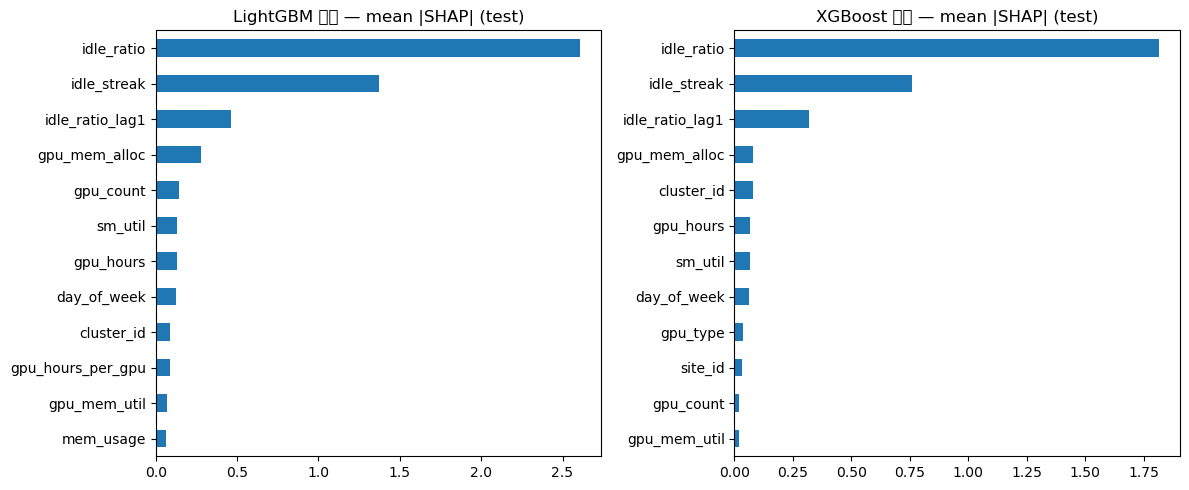

In [17]:
test_wk = df[df["day"].between(140, 146)]
tr = df[df["day"] <= 138]
Xt, yt, _ = split_xyw(test_wk)
shap_rows = {}
for name, kind in [("LightGBM 튜닝", "lgbm"), ("XGBoost 튜닝", "xgb")]:
    fm = fit_model(kind, BEST[kind], tr, device=DEVICES[0])
    Zt = fm.enc.transform(Xt)
    if kind == "xgb":
        bst = fm.model.get_booster(); bst.set_param({"device": f"cuda:{DEVICES[0]}"})
        contrib = bst.predict(xgb.DMatrix(Zt, enable_categorical=True), pred_contribs=True)
    else:
        contrib = np.asarray(fm.model.predict(Zt, pred_contrib=True))
    sd = pd.DataFrame(contrib[:, :-1], columns=Zt.columns)
    shap_rows[name] = sd.abs().mean()
imp = pd.DataFrame(shap_rows)
imp["묶음"] = imp.index.map(lambda c: FEAT_GROUP.get(c, "기타"))
imp = imp.sort_values("LightGBM 튜닝", ascending=False)
imp.to_csv(OUT / "shap_importance.csv")
display(imp.head(12).round(3))
gimp = imp.groupby("묶음")[["LightGBM 튜닝", "XGBoost 튜닝"]].sum().sort_values("LightGBM 튜닝", ascending=False)
display(gimp.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["LightGBM 튜닝", "XGBoost 튜닝"]):
    imp[name].sort_values().tail(12).plot.barh(ax=ax); ax.set_title(f"{name} — mean |SHAP| (test)")
fig.tight_layout(); fig.savefig(OUT / "shap_importance.png", dpi=130); plt.show()

### 4.3 변수 묶음별 운영 이득 (v4 E3 결과 다시 보기)

SHAP 크기와 운영 이득은 같은 것이 아니다. v4에서 LightGBM으로 변수 묶음을 하나씩 더하거나 뺀 결과를 다시 보여준다.
주 정책, 홀드아웃 5주 기준이다.

In [18]:
e3 = pd.read_csv(ROOT / "outputs" / "v4" / "e3_ablation.csv")
e3 = e3[(e3["구간"] == "홀드아웃 5주 (147–180)") & (e3["정책"] == MAIN) & (e3["workload"] == "전체")]
display(e3[["설정", "주별 AP 평균", "Δ회수 GPU-h vs B1", "Δ잘못 회수 GPU-h vs B1", "Δ잘못 회수 건수 vs B1", "ΔF1 vs B1"]].round(4))

,설정,주별 AP 평균,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1,ΔF1 vs B1
3,전체 (23개),0.9455,-6704.3333,-60522.2840,-36,0.0058
9,더하기: 오늘 idle,0.8471,-815.9278,3643.3947,8,-0.0005
15,더하기: 오늘 idle + 이력,0.9287,-4013.6388,14838.1166,79,-0.0022
21,더하기: 오늘 idle + 이력 + 오늘 사용량,0.9361,-3533.8166,-1736.4503,22,-0.0003
27,더하기: 오늘 idle + 이력 + 오늘 사용량 + 규모,0.9378,-11109.2165,-59051.5401,-8,0.0050
33,더하기: 오늘 idle + 이력 + 오늘 사용량 + 규모 + 메타,0.9434,-12838.6774,-65483.9238,-31,0.0055
39,빼기: −이력,0.9382,-34262.5446,-81987.6348,10,0.0043
45,빼기: −오늘 사용량,0.9448,-6500.7556,-60925.1736,-22,0.0059
51,빼기: −규모,0.9459,20416.8282,-33652.2000,-21,0.0067
57,빼기: −메타,0.9414,-4596.1167,-36673.6569,-12,0.0034


### 4.4 workload별 (주 정책)

In [19]:
wl = pd.concat([pooled_view("E1", seg="online"), pooled_view("E1", seg="offline")])
wl.to_csv(OUT / "pooled_by_workload.csv", index=False)
for pool in list(POOLS)[1:2]:
    d = wl[(wl["구간"] == pool) & wl["정책"].isin(["-", MAIN]) & wl["방법"].isin(["Baseline 1: 오늘 idle", *MODELS, FINAL])]
    d = d[~((d["정책"] == "-") & (d["방법"] != "Baseline 1: 오늘 idle"))]
    print(f"=== {pool} ===")
    display(d[["workload", "방법", "F1", "회수 GPU-h", "잘못 회수 GPU-h", "잘못 회수 건수", "Δ회수 GPU-h vs B1",
               "Δ잘못 회수 GPU-h vs B1", "Δ잘못 회수 건수 vs B1"]].round(4))

=== 홀드아웃 5주 (147–180) ===


,workload,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,Δ회수 GPU-h vs B1,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1
4,online,Baseline 1: 오늘 idle,0.8847,465528.8460,57366.4999,368,0.0000,0.0000,0
103,online,Logistic Regression,0.8661,453173.3571,63762.8611,426,-12355.4890,6396.3613,58
157,online,SVM (cuML),0.8773,457241.1571,55709.7778,409,-8287.6890,-1656.7221,41
211,online,Random Forest,0.8794,467713.7405,66501.1446,355,2184.8945,9134.6448,-13
265,online,LightGBM 튜닝,0.8872,467222.0794,56598.7887,359,1693.2334,-767.7111,-9
319,online,XGBoost 튜닝,0.8874,465909.3571,54611.5222,370,380.5111,-2754.9776,2
373,online,최종: LGBM+XGB 평균,0.8905,467738.5072,53241.9222,365,2209.6611,-4124.5776,-3
5,offline,Baseline 1: 오늘 idle,0.6295,204397.9457,189530.4435,45,0.0000,0.0000,0
104,offline,Logistic Regression,0.6290,204324.5290,189941.9658,49,-73.4167,411.5222,4
158,offline,SVM (cuML),0.6049,193401.1677,190636.3547,49,-10996.7779,1105.9111,4


## 5. 실제 cold start — 5분 단위 시뮬레이션 (test 주)

일 단위 라벨 대신, 회수한 app이 **다음날 실제로 언제 처음 활동했는지**를 5분 표로 확인한다.
- 가정: day t+1 시작에 회수한다. 첫 활동 5분 창에서 cold start가 1건 생기고, 그날 나머지는 다시 올려 둔다.
- 회수 GPU-h = 첫 활동 전까지의 `gpu_count × 5분` 합이다. 활동이 없으면 하루 전체를 센다.
- 5분 표가 140–146일뿐이라 오늘 = 140–145인 행만 쓴다.
- 집계표는 `scripts/sim_5min_samecount.py`가 만든 `outputs/final/sim_5min_agg.parquet`를 쓴다. 없으면 여기서 만든다.

In [20]:
sys.path.insert(0, str(ROOT / "scripts"))
from sim_5min_samecount import AGG, SQL, sim_table
if AGG.exists():
    agg = pd.read_parquet(AGG)
else:
    from gpu_reclaim.db import connect
    agg = connect(threads=16, memory_limit="64GB").sql(SQL).df()
    agg.to_parquet(AGG, index=False)
W0 = WK[0]; assert W0["name"] == "140–146"
m = W0["day"] <= 145
ts = pd.DataFrame({"app_id": W0["wk"]["app_id"].astype(str).values[m], "day": W0["day"][m],
                   "y": W0["yk"][m], "w": W0["wk_w"][m]})
a = agg.copy(); a["app_id"] = a["app_id"].astype(str); a["day"] = a["day"] - 1
ts = ts.merge(a, on=["app_id", "day"], how="left")
assert len(ts) == m.sum()
print(f"대상 {len(ts):,}행, 5분 기록 있음 {ts['gpu_h_5min'].notna().mean() * 100:.1f}%")
methods = {"Baseline 1: 오늘 idle": W0["b1k"][m].astype(bool)}
for name in [*MODELS, FINAL]:
    methods[f"{name} | {MAIN}"] = PRED_STORE[("E1", "기본", name, 0, MAIN)][0][m].astype(bool)
methods[f"{FINAL} | 위험 맞춤 GPU-h (직전 주)"] = PRED_STORE[("E1", "기본", FINAL, 0, "위험 맞춤 GPU-h (직전 주)")][0][m].astype(bool)
methods["(상한) 전부 회수"] = np.ones(len(ts), dtype=bool)
sim_res = sim_table(ts, methods)
sim_res.to_csv(OUT / "sim_5min_test.csv", index=False)
display(sim_res.round(3))

대상 18,297행, 5분 기록 있음 100.0%


,방법,회수 app-day,cold start 건수,cold start 비율,첫 활동까지 시간 중앙값(h),회수 GPU-h (첫 활동 전까지),cold start app의 하루 GPU-h,일 단위 잘못 회수 건수,일 단위 잘못 회수 GPU-h,Δ회수 app-day vs B1,Δcold start 건수 vs B1,Δ회수 GPU-h (첫 활동 전까지) vs B1,Δcold start app의 하루 GPU-h vs B1,Δ일 단위 잘못 회수 GPU-h vs B1
0,Baseline 1: 오늘 idle,5809,2453,0.422,5.500,302749.083,406005.833,242,52928.295,0,0,0.000,0.000,0.000
1,Logistic Regression | 같은 날 B1과 같은 개수,5809,2538,0.437,4.917,276912.667,412350.833,296,47581.878,0,85,-25836.417,6345.000,-5346.417
2,SVM (cuML) | 같은 날 B1과 같은 개수,5809,2517,0.433,5.000,282186.583,356565.250,292,46030.745,0,64,-20562.500,-49440.583,-6897.550
3,Random Forest | 같은 날 B1과 같은 개수,5809,2448,0.421,5.583,303085.333,399631.250,237,52313.006,0,-5,336.250,-6374.583,-615.289
4,LightGBM 튜닝 | 같은 날 B1과 같은 개수,5809,2456,0.423,5.500,300727.583,404731.083,242,51946.406,0,3,-2021.500,-1274.750,-981.889
5,XGBoost 튜닝 | 같은 날 B1과 같은 개수,5809,2453,0.422,5.500,300992.667,397696.583,245,53000.145,0,0,-1756.417,-8309.250,71.850
6,최종: LGBM+XGB 평균 | 같은 날 B1과 같은 개수,5809,2453,0.422,5.500,302338.917,405549.083,244,52904.239,0,0,-410.167,-456.750,-24.056
7,최종: LGBM+XGB 평균 | 위험 맞춤 GPU-h (직전 주),5888,2523,0.428,5.167,303372.583,414644.333,274,54948.250,79,70,623.500,8638.500,2019.956
8,(상한) 전부 회수,18297,13271,0.725,0.000,1917406.083,8257752.750,12317,9180535.491,12488,10818,1614657.000,7851746.917,9127607.196


## 6. 가치 — 운영 관점에서 얼마인가

홀드아웃 5주(34일)를 주 단위로 환산한다. `GPU 대수 환산` = 주당 GPU-h ÷ 168시간이다. 일주일 내내 비워 둘 수 있는 GPU 대수에 해당한다.

In [21]:
pool = "홀드아웃 5주 (147–180)"
n_days = sum(W["b"] - W["a"] + 1 for W in WK if W["name"] in POOLS[pool])
per_week = 7 / n_days
total_next = sum(W["wk_w"].sum() for W in WK if W["name"] in POOLS[pool])
r = res[(res["구간"] == pool)].set_index(["방법", "정책"])
b = r.loc[("Baseline 1: 오늘 idle", "-")]
f = r.loc[(FINAL, MAIN)]
value = pd.DataFrame({
    "Baseline 1": [b["회수 GPU-h"], b["잘못 회수 GPU-h"], b["잘못 회수 건수"]],
    "최종 모델": [f["회수 GPU-h"], f["잘못 회수 GPU-h"], f["잘못 회수 건수"]],
}, index=["회수 GPU-h (내일 idle인 app)", "잘못 회수로 깨우는 GPU-h", "잘못 회수 건수"]) * per_week
value["차이"] = value["최종 모델"] - value["Baseline 1"]
value["변화율"] = value["차이"] / value["Baseline 1"]
value.loc["GPU 대수 환산 (회수)"] = [b["회수 GPU-h"] * per_week / 168, f["회수 GPU-h"] * per_week / 168, np.nan, np.nan]
value["차이"] = value["최종 모델"] - value["Baseline 1"]
print(f"주당 환산 (홀드아웃 {n_days}일 기준). 이 기간 전체 내일 GPU-h 중 B1 회수 비중: {b['회수 GPU-h'] / total_next * 100:.1f}%")
display(value.round(3))
value.to_csv(OUT / "value_per_week.csv")

주당 환산 (홀드아웃 7일 기준). 이 기간 전체 내일 GPU-h 중 B1 회수 비중: 6.9%


,Baseline 1,최종 모델,차이,변화율
회수 GPU-h (내일 idle인 app),669926.792,672013.247,2086.456,0.003
잘못 회수로 깨우는 GPU-h,246896.943,242565.882,-4331.061,-0.018
잘못 회수 건수,413.000,408.000,-5.000,-0.012
GPU 대수 환산 (회수),3987.659,4000.079,12.419,NaN


## 7. 요약

In [22]:
rows = []
for pool in POOLS:
    for meth, pol in [("Baseline 1: 오늘 idle", "-"), ("Baseline 2: sm_util 하위 N", "-")] + [(m_, MAIN) for m_ in [*MODELS, FINAL]]:
        q = res[(res["구간"] == pool) & (res["방법"] == meth) & (res["정책"] == pol)]
        if len(q):
            q = q.iloc[0]
            rows.append({"구간": pool, "방법": meth, "F1": q["F1"], "회수 GPU-h": q["회수 GPU-h"], "잘못 회수 GPU-h": q["잘못 회수 GPU-h"],
                         "잘못 회수 건수": q["잘못 회수 건수"], "Δ잘못 회수 GPU-h vs B1": q["Δ잘못 회수 GPU-h vs B1"],
                         "Δ잘못 회수 건수 vs B1": q["Δ잘못 회수 건수 vs B1"]})
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "summary.csv", index=False)
display(summary.round(4))

# 점수 저장 (주별 행 순서는 df에서 그 주를 고른 순서)
keys = pd.concat([pd.DataFrame({"주": W["name"], "row_index": W["wk"].index, "app_id": W["wk"]["app_id"].astype(str).values,
                                "day": W["day"], "y": W["yk"], "w": W["wk_w"], "b1": W["b1k"]}) for W in WK], ignore_index=True)
sc_cols = {n: np.concatenate([SC[n][i][1] for i in range(len(WK))]).astype("float32") for n in SC}
pd.concat([keys, pd.DataFrame(sc_cols)], axis=1).to_parquet(OUT / "scores.parquet", index=False)
print("저장 위치:", OUT, "| 전체", elapsed())

,구간,방법,F1,회수 GPU-h,잘못 회수 GPU-h,잘못 회수 건수,Δ잘못 회수 GPU-h vs B1,Δ잘못 회수 건수 vs B1
0,test 주 (140–146),Baseline 1: 오늘 idle,0.8797,6.616927e+05,99261.1949,342,0.0000,0
1,test 주 (140–146),Baseline 2: sm_util 하위 N,0.6189,5.233459e+05,424317.0456,2554,325055.8507,2212
2,test 주 (140–146),Logistic Regression,0.8899,6.486561e+05,65675.4450,397,-33585.7498,55
3,test 주 (140–146),SVM (cuML),0.8532,5.991608e+05,62004.7450,395,-37256.4499,53
4,test 주 (140–146),Random Forest,0.8636,6.563934e+05,120273.9776,334,21012.7828,-8
5,test 주 (140–146),LightGBM 튜닝,0.8794,6.604087e+05,98074.5893,340,-1186.6056,-2
6,test 주 (140–146),XGBoost 튜닝,0.8735,6.534222e+05,99213.0504,342,-48.1444,0
7,test 주 (140–146),최종: LGBM+XGB 평균,0.8796,6.615144e+05,99141.2115,342,-119.9833,0
8,홀드아웃 5주 (147–180),Baseline 1: 오늘 idle,0.7873,6.699268e+05,246896.9434,413,0.0000,0
9,홀드아웃 5주 (147–180),Baseline 2: sm_util 하위 N,0.5521,5.168676e+05,570604.9335,2496,323707.9901,2083


저장 위치: /ssd/jylee/gpu-reclaim/outputs/final | 전체 9.7분
